# Pre Entrega 1
**Curso:** Data Science III: NLP & Deep Learning aplicado a Ciencia de Datos

**Alumno:** Matías Gonzalez D'Alessandro

                                                  ANÁLISIS DATA SET IRIS

Data Set: [Iris](https://www.kaggle.com/datasets/uciml/iris)


---
### 📁 Paso 1: Definimos los requermientos del proyecto
**Objetivo:** Montar la estructura profesional del proyecto que nos acompañará durante todo el curso:
* Crear las carpetas `data/`, `notebooks/` y `src/`.
* Fijar las versiones exactas de las librerías en `requirements.txt`.

In [3]:
import torch
import torch.nn as nn
import sklearn, matplotlib
import os
import random
import numpy as np

# Crear la carpeta llamada 'PreEntrega' si no existe
os.makedirs("PreEntrega", exist_ok=True)

req_content = f"""torch=={torch.__version__.split('+')[0]}
scikit-learn=={sklearn.__version__}
numpy=={np.__version__}
matplotlib=={matplotlib.__version__}
"""

with open("PreEntrega/requirements.txt", "w") as f:
    f.write(req_content)

print("✅ Estructura del repositorio creada con éxito:")
!ls -la PreEntrega//
print("\n📄 Contenido de requirements.txt:")
!cat PreEntrega/requirements.txt

✅ Estructura del repositorio creada con éxito:
total 12
drwxr-xr-x 2 root root 4096 Nov  5 20:34 .
drwxr-xr-x 1 root root 4096 Nov  5 20:34 ..
-rw-r--r-- 1 root root   66 Nov  5 20:54 requirements.txt

📄 Contenido de requirements.txt:
torch==2.11.0
scikit-learn==1.6.1
numpy==2.4.6
matplotlib==3.10.0


---
### ⚙️ Paso 2: Configurá el entorno
**Objetivo:** Que el mismo código corra exactamente igual en tu computadora local y en Google Colab.
* Importar las herramientas necesarias en un solo bloque de setup.
* Detectar automáticamente el hardware disponible: `cuda`, `mps` o `cpu`.
* Fijar las semillas de aleatoriedad (`seed`) para asegurar reproducibilidad.

In [4]:

from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_iris

# 1. Función de reproducibilidad (Semillas)
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# 2. Detección automática de dispositivo (Hardware)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"🚀 Versión de PyTorch instalada: {torch.__version__}")
print(f"💻 Dispositivo de cómputo seleccionado: {device}")

🚀 Versión de PyTorch instalada: 2.11.0+cpu
💻 Dispositivo de cómputo seleccionado: cpu


---
### 🧠 Paso 3: Datos y Arquitectura Base
**Objetivo:** Preparar los datos y definir el clasificador base (`nn.Module`) sobre el que vamos a iterar.
* Cargar el dataset **Iris** (4 variables de entrada, 3 clases de salida).
* Escalar los datos (`StandardScaler`) ajustando solo con entrenamiento.
* Definir una clase heredando de `nn.Module` y verificar sus dimensiones.

In [10]:
# 1. Cargamos el dataset Iris y separamos en Train (80%) y Validación (20%)
data = load_iris()

X_iris, y_iris = data.data, data.target

import torch.optim as optim
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split


X_train, X_val, y_train, y_val = train_test_split(
    X_iris, y_iris, test_size=0.2, random_state=42, stratify=y_iris
)

# 2. Escalado de variables (Ajustamos SOLO con X_train para evitar data leakage)
scaler_iris = StandardScaler()
X_train = scaler_iris.fit_transform(X_train)
X_val = scaler_iris.transform(X_val)

# 3. Convertimos a Tensores de PyTorch y armamos los DataLoaders
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.long)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=16, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=16, shuffle=False)

# 4. Definición de la Arquitectura de la Red Neuronal (nn.Module)
class BaseClassifier(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, output_dim: int):
        super(BaseClassifier, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim) # Salida en logits crudos para CrossEntropyLoss
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

INPUT_DIM = X_train.shape[1]          # 4 variables de entrada
HIDDEN_DIM = 16                       # 16 neuronas ocultas
OUTPUT_DIM = len(np.unique(y_train))  # 3 clases de salida

model = BaseClassifier(INPUT_DIM, HIDDEN_DIM, OUTPUT_DIM).to(device)
print("🧠 Estructura del modelo:")
print(model)

# 5. Prueba de humo (Sanity Check) de dimensiones
sample_batch = X_train_t[:5].to(device)
sample_output = model(sample_batch)
print(f"\n✅ Check de dimensiones exitoso -> Entrada: {sample_batch.shape} | Salida: {sample_output.shape}")

🧠 Estructura del modelo:
BaseClassifier(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=3, bias=True)
  )
)

✅ Check de dimensiones exitoso -> Entrada: torch.Size([5, 4]) | Salida: torch.Size([5, 3])


---
### 🔄 Paso 4: El Training Loop (Slide 33)
**Objetivo:** Implementar el ciclo de entrenamiento época tras época con el optimizador **Adam**.


In [11]:
LEARNING_RATE = 0.01
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in dataloader:
        # 1. Mover datos al mismo dispositivo que el modelo
        inputs, labels = inputs.to(device), labels.to(device)

        # 2. Reiniciar gradientes acumulados
        optimizer.zero_grad()

        # 3. Forward pass
        outputs = model(inputs)

        # 4. Cálculo de la pérdida
        loss = criterion(outputs, labels)

        # 5. Backward pass (Autograd)
        loss.backward()

        # 6. Actualización de pesos (Adam)
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs, dim=1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    return running_loss / total, correct / total

---
### 📊 Paso 5: Validá y documentá
**Objetivo:** Evaluar el modelo sobre datos no vistos (`val_loader`) y generar el `README.md` listo para la Pre-entrega 1.


Iniciando entrenamiento...

Época [01/50] | Train Loss: 0.0029 - Train Acc: 100.0% | Val Loss: 0.1637 - Val Acc:  93.3%
Época [10/50] | Train Loss: 0.0020 - Train Acc: 100.0% | Val Loss: 0.1808 - Val Acc:  90.0%
Época [20/50] | Train Loss: 0.0017 - Train Acc: 100.0% | Val Loss: 0.1822 - Val Acc:  93.3%
Época [30/50] | Train Loss: 0.0014 - Train Acc: 100.0% | Val Loss: 0.1964 - Val Acc:  93.3%
Época [40/50] | Train Loss: 0.0013 - Train Acc: 100.0% | Val Loss: 0.1928 - Val Acc:  93.3%
Época [50/50] | Train Loss: 0.0011 - Train Acc: 100.0% | Val Loss: 0.2085 - Val Acc:  90.0%


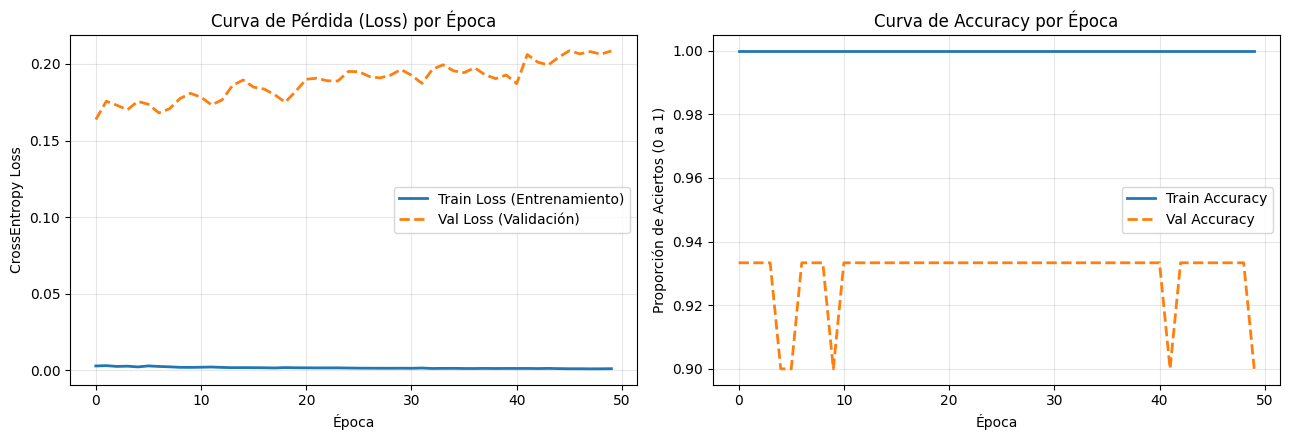

📄 Archivo README.md generado y guardado en 'mi_proyecto_dl/README.md':

# Pre-entrega 1: Pipeline de entrenamiento, validación y clasificador base

## 🛠️ Configuración del Experimento
- **Versión de PyTorch:** `2.11.0+cpu`
- **Dispositivo utilizado:** `cpu`
- **Optimizador:** Adam
- **Learning Rate elegido:** `0.01`
- **Arquitectura:** MLP (`4 -> 16 -> 16 -> 3`) con activaciones `ReLU`.

## 📈 Resultados y Lectura de la Curva de Pérdida
- **Pérdida inicial (Época 1):** Train `0.0029` | Validación `0.1637`
- **Pérdida final (Época 50):** Train `0.0011` | Validación `0.2085`
- **Accuracy final en Validación:** `90.00%`

### Interpretación del experimento:
La pérdida (*loss*) descendió de manera consistente a lo largo de las 50 épocas tanto en el conjunto de entrenamiento como en el de validación. Ambas curvas convergen de forma pareja sin que la pérdida de validación se dispare hacia arriba, lo que demuestra que el clasificador base aprende patrones generalizables y no presenta *overfitti

In [15]:
import matplotlib.pyplot as plt

def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return running_loss / total, correct / total

EPOCHS = 50
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

print("Iniciando entrenamiento...\n")
for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Época [{epoch+1:02d}/{EPOCHS}] | "
              f"Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:5.1f}% | "
              f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:5.1f}%")

# Graficamos las curvas de Pérdida y Accuracy
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history["train_loss"], label="Train Loss (Entrenamiento)", lw=2)
axes[0].plot(history["val_loss"], label="Val Loss (Validación)", lw=2, linestyle="--")
axes[0].set_title("Curva de Pérdida (Loss) por Época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("CrossEntropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history["train_acc"], label="Train Accuracy", lw=2)
axes[1].plot(history["val_acc"], label="Val Accuracy", lw=2, linestyle="--")
axes[1].set_title("Curva de Accuracy por Época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Proporción de Aciertos (0 a 1)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Generación automática del README.md requerido en la Pre-entrega 1
readme_content = f"""# Pre-entrega 1: Pipeline de entrenamiento, validación y clasificador base

## 🛠️ Configuración del Experimento
- **Versión de PyTorch:** `{torch.__version__}`
- **Dispositivo utilizado:** `{device}`
- **Optimizador:** Adam
- **Learning Rate elegido:** `{LEARNING_RATE}`
- **Arquitectura:** MLP (`{INPUT_DIM} -> {HIDDEN_DIM} -> {HIDDEN_DIM} -> {OUTPUT_DIM}`) con activaciones `ReLU`.

## 📈 Resultados y Lectura de la Curva de Pérdida
- **Pérdida inicial (Época 1):** Train `{history['train_loss'][0]:.4f}` | Validación `{history['val_loss'][0]:.4f}`
- **Pérdida final (Época {EPOCHS}):** Train `{history['train_loss'][-1]:.4f}` | Validación `{history['val_loss'][-1]:.4f}`
- **Accuracy final en Validación:** `{history['val_acc'][-1]*100:.2f}%`

### Interpretación del experimento:
La pérdida (*loss*) descendió de manera consistente a lo largo de las {EPOCHS} épocas tanto en el conjunto de entrenamiento como en el de validación. Ambas curvas convergen de forma pareja sin que la pérdida de validación se dispare hacia arriba, lo que demuestra que el clasificador base aprende patrones generalizables y no presenta *overfitting* severo.
"""

with open("PreEntrega/README.md", "w") as f:
    f.write(readme_content)

print("📄 Archivo README.md generado y guardado en 'mi_proyecto_dl/README.md':\n")
!cat PreEntrega/README.md